# Defferential gene expression analysis (DE)

In [77]:
#load packages
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import gc
import os
from matplotlib.pyplot import rc_context
import gseapy

sc.settings.verbosity = 3             
sc.settings.set_figure_params(dpi=100,figsize=(4,4))
sc.set_figure_params(scanpy=True, fontsize=8, dpi_save=180, format='svg', transparent=True)

In [3]:
my_c = ['#fe864a', '#c9d179', '#95d0fc', '#fbdd7e', '#388004', '#c760ff', '#76cd26', '#ffbacd', '#d6b4fc',
        '#cfaf7b','#8b88f8', '#acc2d9', '#894585', '#82cbb2', '#d99b82', '#fdee73', '#5170d7', '#ffd8b1', 
        '#b7e1a1', '#82a67d', '#b7fffa', '#b790d4']

# Data loading

In [ ]:
adata_raw = sc.read_h5ad('Postnatal_noDBL_raw_annotated.h5ad')

In [ ]:
adata = sc.read_h5ad('Postnatal_noDBL_filtered_clustered_annotated.h5ad')

In [6]:
adata_raw

AnnData object with n_obs × n_vars = 41372 × 32285
    obs: 'Age', 'Gender', 'Project', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_Mito', 'pct_counts_Mito', 'total_counts_Ribo', 'pct_counts_Ribo', 'total_counts_Hb', 'pct_counts_Hb', 'percent_chrY', 'Xist-counts', 'S_score', 'G2M_score', 'phase', 'Sub_cell_type', 'Cell_type'
    var: 'gene_ids', 'feature_types', 'genome', 'Mito', 'Ribo', 'Hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    obsm: 'X_harmony', 'X_pca', 'X_umap'

In [7]:
adata

AnnData object with n_obs × n_vars = 41372 × 32285
    obs: 'Age', 'Gender', 'Project', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_Mito', 'pct_counts_Mito', 'total_counts_Ribo', 'pct_counts_Ribo', 'total_counts_Hb', 'pct_counts_Hb', 'percent_chrY', 'Xist-counts', 'S_score', 'G2M_score', 'phase', 'Sub_cell_type', 'Cell_type', 'n_counts', 'P2/P3', 'P11', 'P60'
    var: 'gene_ids', 'feature_types', 'genome', 'Mito', 'Ribo', 'Hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'Age_colors', 'Cell_type_colors', 'P11_colors', 'P2', 'P60_colors', 'Sub_cell_type_colors', 'batch_colors', 'dendrogram_Cell_type', 'log1p', 'rank_genes_groups', 'wilcoxon_Cell_type'
    obsm: 'X_harmony', 'X_pca', 'X_umap'

/proj/snic2020-15-248/private/Analysis/Monica/myconda_ens/rp_scrnaseq/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/proj/snic2020-15-248/private/Analysis/Monica/myconda_ens/rp_scrnaseq/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


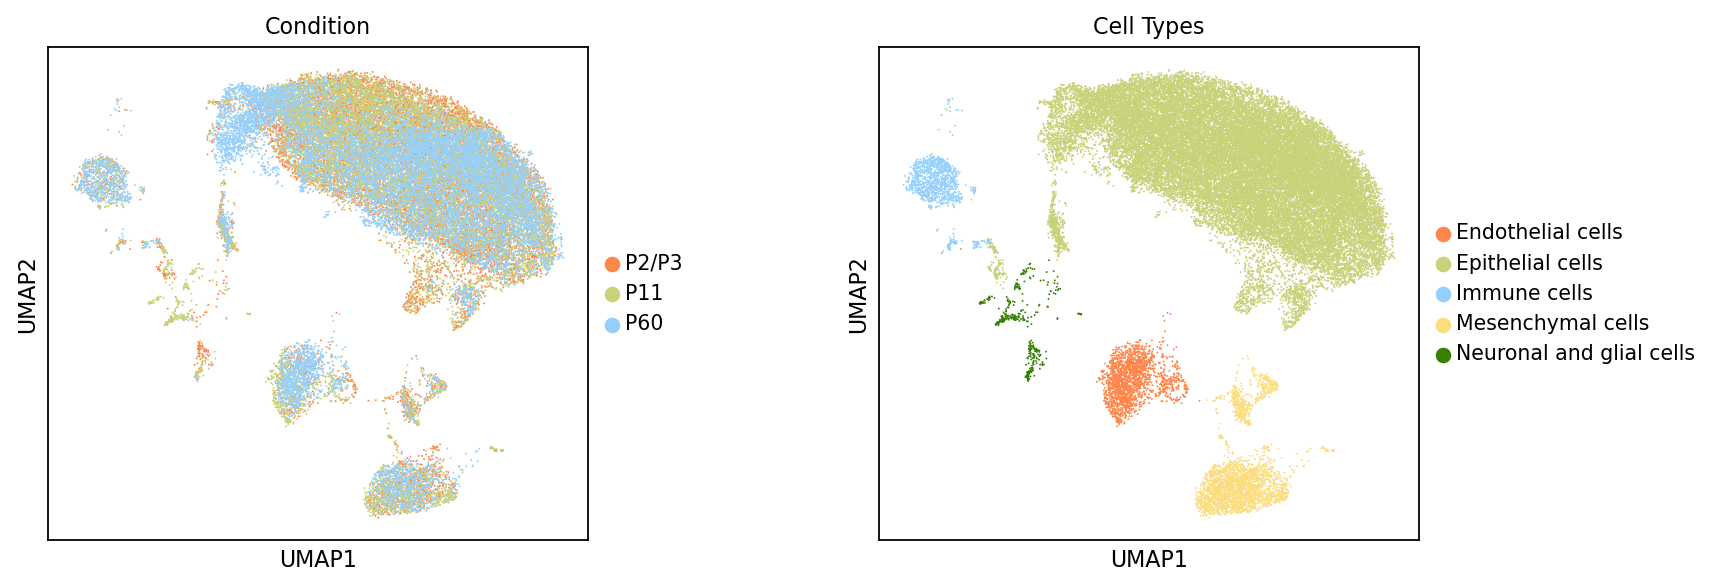

In [8]:
sc.pl.umap(adata, color=['Age','Cell_type'], wspace=0.4, title = ['Condition','Cell Types'])

**For DGE analysis we would like to run with all genes, but on normalized values, so we will have to revert back to the raw matrix and renormalize.**

In [10]:
sc.pp.normalize_per_cell(adata,counts_per_cell_after=1e4)
sc.pp.log1p(adata)
adata.layers['scaled'] = sc.pp.scale(adata, copy=True).X

normalizing by total count per cell
    finished (0:00:05): normalized adata.X and added    'n_counts', counts per cell before normalization (adata.obs)
... as `zero_center=True`, sparse input is densified and may lead to large memory consumption


In [11]:
sc.tl.rank_genes_groups(adata,'Cell_type', method='wilcoxon', key_added='wilcoxon_Cell_type')

ranking genes
    finished: added to `.uns['wilcoxon_Cell_type']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:03:47)


In [12]:
sc.tl.filter_rank_genes_groups(adata, groupby='Cell_type', key = "wilcoxon_Cell_type", 
                               key_added='wilcoxon_filtered_Cell_type',min_in_group_fraction=0.1,
                               max_out_group_fraction=0.5,min_fold_change=0.5)

Filtering genes using: min_in_group_fraction: 0.1 min_fold_change: 0.5, max_out_group_fraction: 0.5


In [13]:
sc.tl.dendrogram(adata, groupby = "Cell_type", use_rep='X_harmony')

Storing dendrogram info using `.uns['dendrogram_Cell_type']`


/proj/snic2020-15-248/private/Analysis/Monica/myconda_ens/rp_scrnaseq/lib/python3.8/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


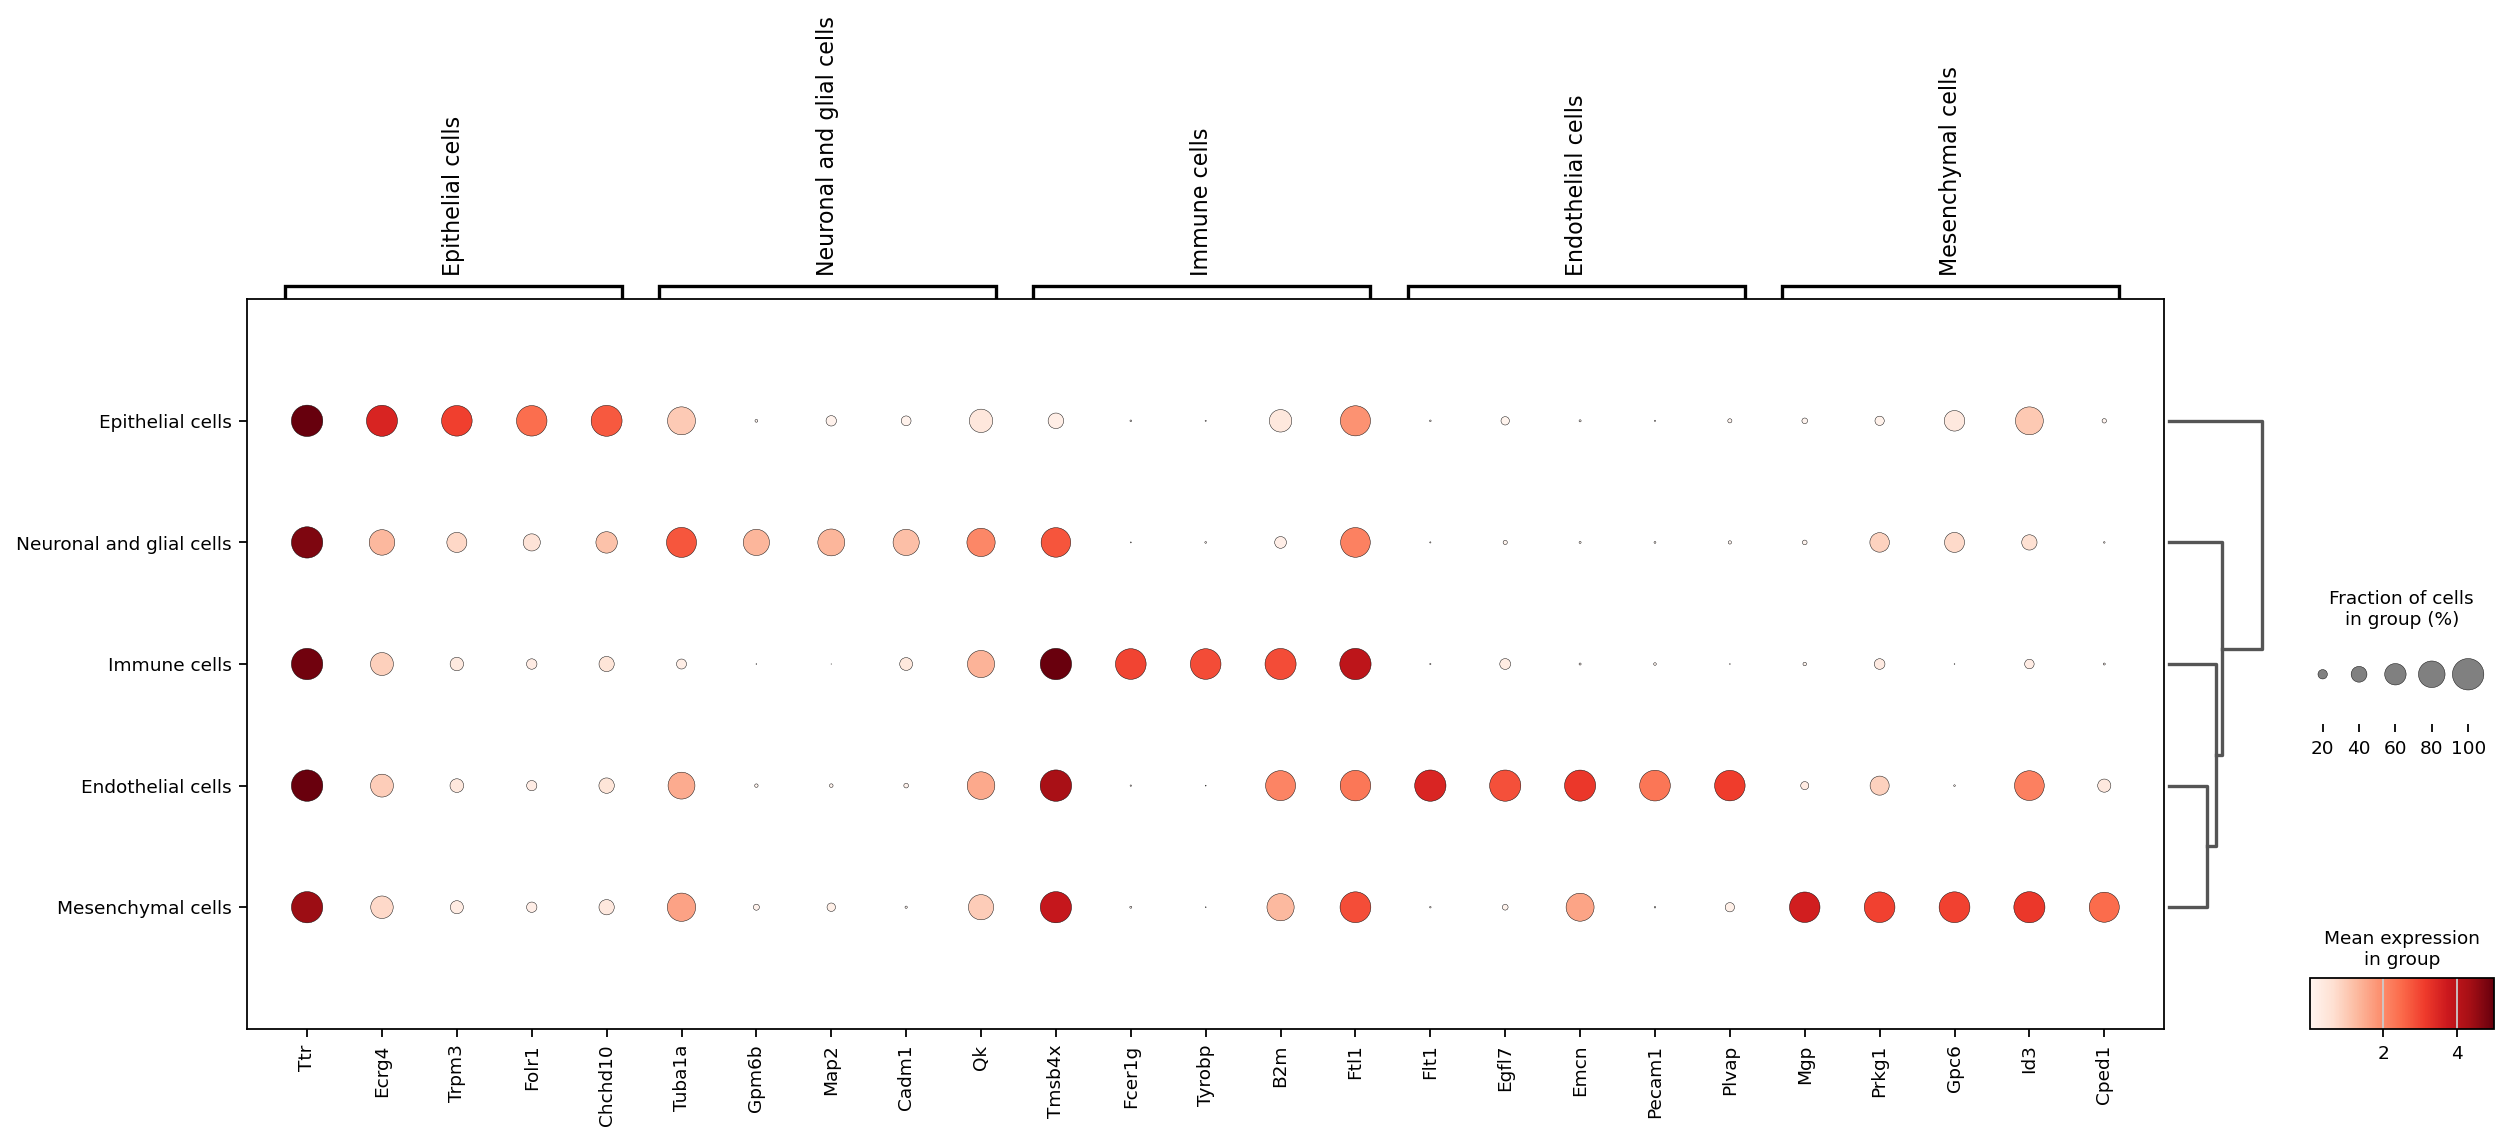

In [14]:
sc.pl.rank_genes_groups_dotplot(adata, n_genes=5, key='wilcoxon_Cell_type', groupby='Cell_type', show=True, 
                                figsize=(18,6), dendrogram=True, vmax=5)

In [15]:
markers = ['Folr1', 'Clic6', 'Otx2', 'Krt18',
           'Sox6', 'Ptprz1', 'Mbp', 'Plp1',
           'C1qa', 'C1qb', 'Fcer1g', 'C1qc',
           'Flt1', 'Plvap', 'Pecam1', 'Ly6a',
           'Dcn', 'Itga8', 'Col3a1', 'Lum']

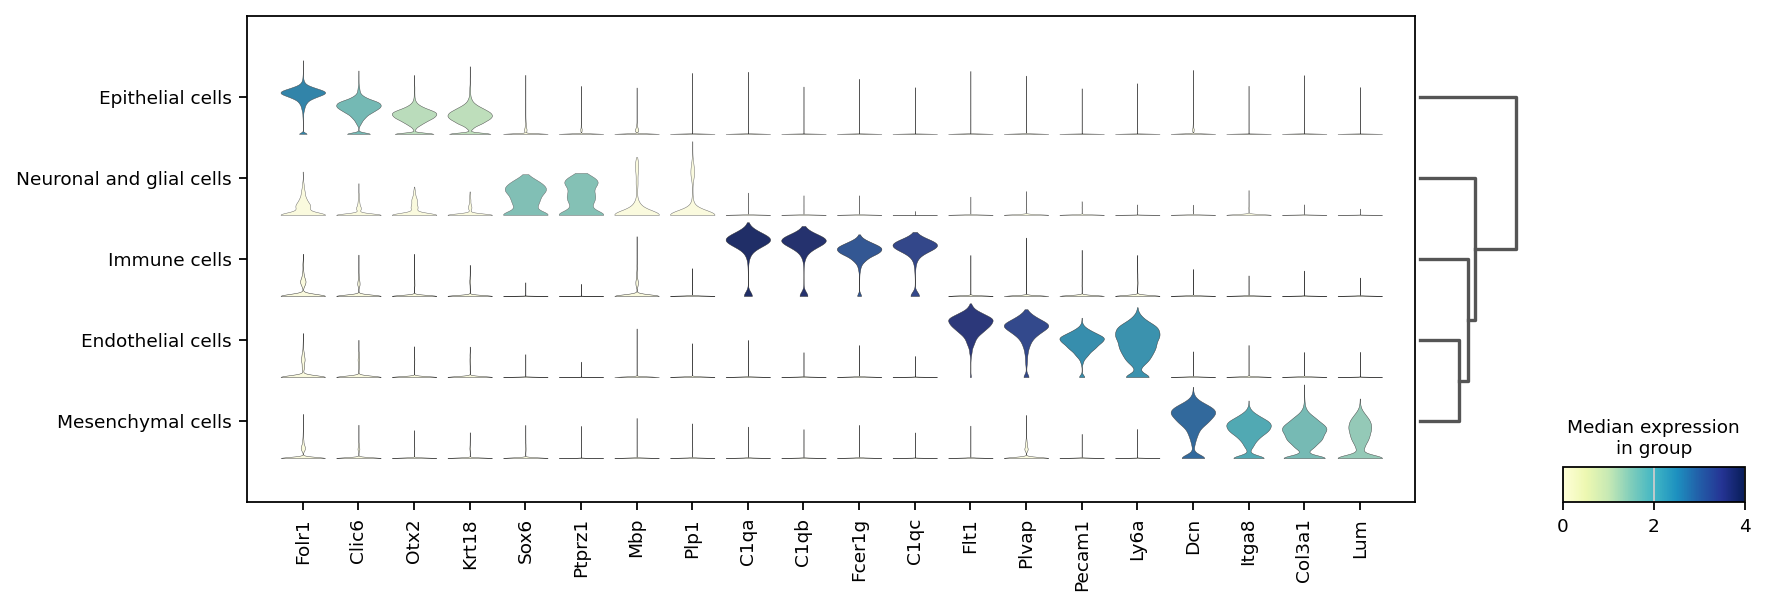

In [16]:
sc.pl.rank_genes_groups_stacked_violin(adata, var_names=markers,cmap='YlGnBu', groupby='Cell_type',
                                       key='wilcoxon_Cell_type', figsize=(12,4), vmax=4)

# Epithelial cells

In [18]:
Epithelial_cells_all = adata_raw[adata_raw.obs["Sub_cell_type"].isin(['Epithelial cells', 'Epithelial cells Tbc1d1+', 
                                                                  'Ciliogenesis', 'Epithelial cells Gpx3+', 
                                                                  'Epithelial cells Gata3+'])]

In [20]:
Epithelial_cells_all_p2p3 = Epithelial_cells_all[Epithelial_cells_all.obs['Age']=='P2/P3']

Epithelial_cells_all_p11 = Epithelial_cells_all[Epithelial_cells_all.obs['Age']=='P11']

Epithelial_cells_all_p60 = Epithelial_cells_all[Epithelial_cells_all.obs['Age']=='P60']

In [22]:
Epithelial_cells_all_2_3 = [Epithelial_cells_all_2_3 for Epithelial_cells_all_2_3 in Epithelial_cells_all_p2p3.obs_names]

Epithelial_cells_all_11 = [Epithelial_cells_all_11 for Epithelial_cells_all_11 in Epithelial_cells_all_p11.obs_names]

Epithelial_cells_all_60 = [Epithelial_cells_all_60 for Epithelial_cells_all_60 in Epithelial_cells_all_p60.obs_names]


print(f"Epithelial_cells from P2/P3 {len(Epithelial_cells_all_2_3)}\nEpithelial_cells from P11 {len(Epithelial_cells_all_11)}\nEpithelial_cells from P60 {len(Epithelial_cells_all_60)}")

Epithelial_cells from P2/P3 11439
Epithelial_cells from P11 12405
Epithelial_cells from P60 11072


In [23]:
import random
random_Epithelial_cells_p2p3 = random.sample(Epithelial_cells_all_2_3, 11000)

random_Epithelial_cells_p11 = random.sample(Epithelial_cells_all_11, 11000)

random_Epithelial_cells_p60 = random.sample(Epithelial_cells_all_60, 11000)

print(f"Epithelial_cells from P2/P3 {len(random_Epithelial_cells_p2p3)}\nEpithelial_cells from P11 {len(random_Epithelial_cells_p11)}\nEpithelial_cells from P60 {len(random_Epithelial_cells_p60)}")

Epithelial_cells from P2/P3 11000
Epithelial_cells from P11 11000
Epithelial_cells from P60 11000


In [25]:
random_Epithelial_cells = random_Epithelial_cells_p2p3 + random_Epithelial_cells_p11 + random_Epithelial_cells_p60

In [26]:
len(random_Epithelial_cells)

33000

In [28]:
Epithelial_cells = Epithelial_cells_all[random_Epithelial_cells,:]

In [29]:
sc.pp.normalize_per_cell(Epithelial_cells,counts_per_cell_after=1e4)
sc.pp.log1p(Epithelial_cells)
Epithelial_cells.layers['scaled'] = sc.pp.scale(Epithelial_cells, copy=True).X

normalizing by total count per cell


/proj/snic2020-15-248/private/Analysis/Monica/myconda_ens/rp_scrnaseq/lib/python3.8/site-packages/scanpy/preprocessing/_simple.py:524: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[key_n_counts] = counts_per_cell


    finished (0:00:05): normalized adata.X and added    'n_counts', counts per cell before normalization (adata.obs)
... as `zero_center=True`, sparse input is densified and may lead to large memory consumption


## QC check

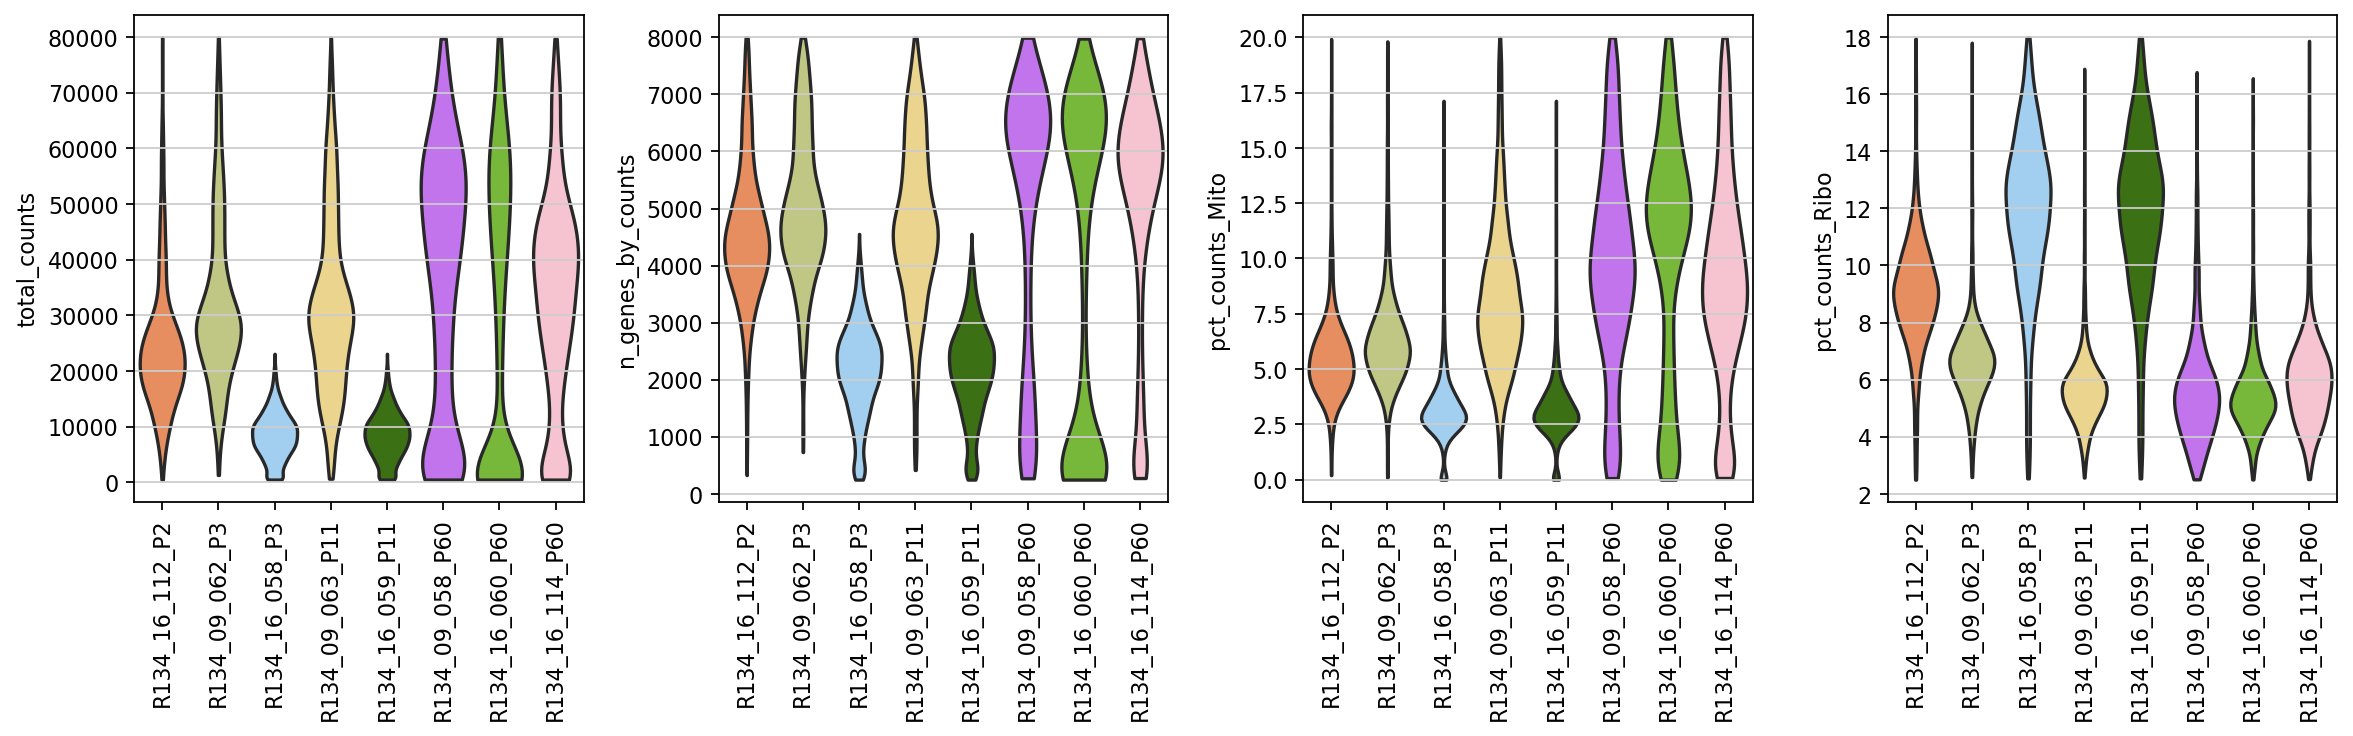

normalizing counts per cell
    finished (0:00:01)


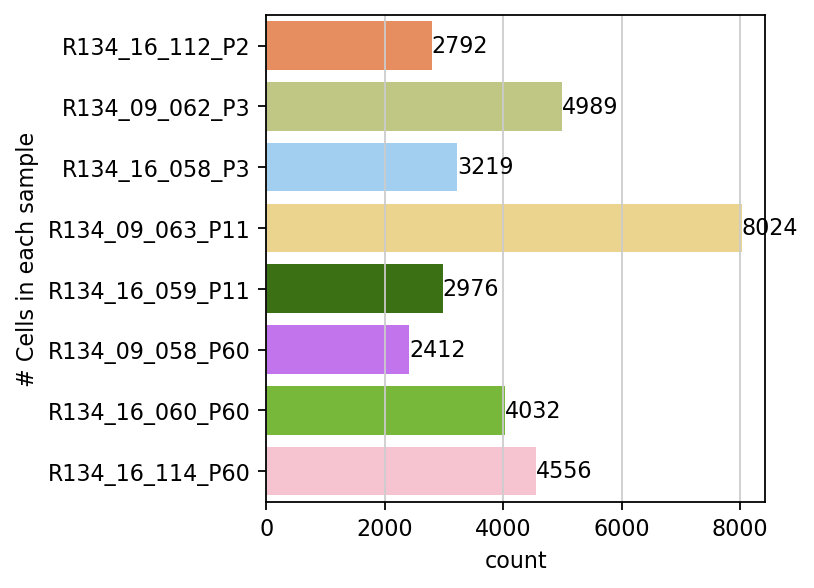

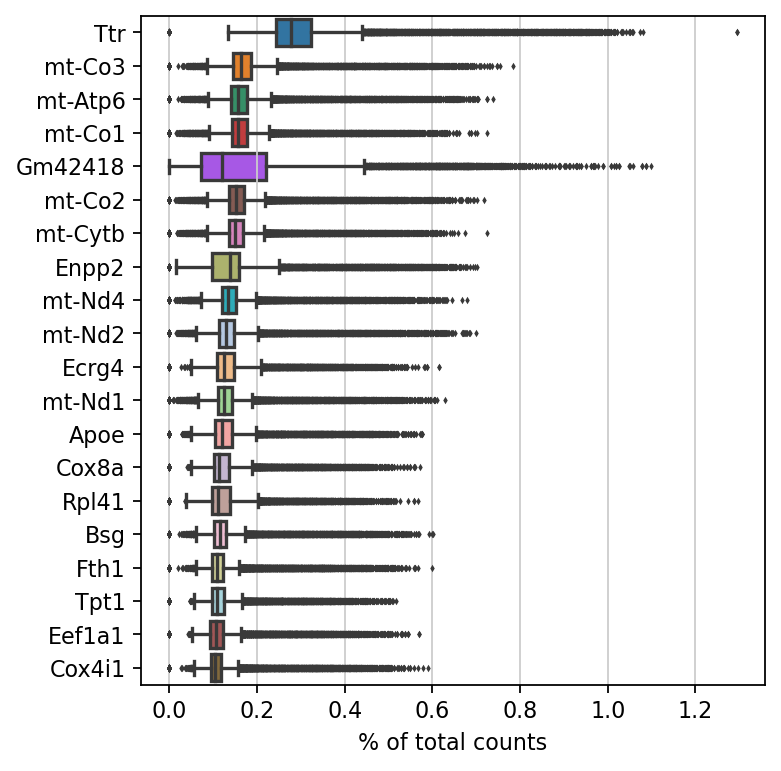

In [30]:
sc.pl.violin(Epithelial_cells, keys=['total_counts', 'n_genes_by_counts', 'pct_counts_Mito', 'pct_counts_Ribo'],
                 rotation=90, stripplot=False, jitter=0.4, multi_panel=True, groupby='batch', palette=my_c)

ax = sns.countplot(y='batch', data=Epithelial_cells.obs, palette=my_c)
ax.set_ylabel('# Cells in each sample')

for container in ax.containers:
    ax.bar_label(container)
    
sc.pl.highest_expr_genes(Epithelial_cells, n_top=20)

## DGEs from wilcoxon

In [31]:
sc.tl.rank_genes_groups(Epithelial_cells, groupby='Age', groups=['P2/P3','P60'], reference='P60',
                        method='wilcoxon', key_added="wilcoxon_P2_P3vsP60", pts=True, use_raw=False)
sc.tl.rank_genes_groups(Epithelial_cells, groupby='Age', groups=['P2/P3','P60'], reference='P2/P3',
                        method='wilcoxon', key_added="wilcoxon_P60vsP2_P3", pts=True, use_raw=False)

sc.tl.rank_genes_groups(Epithelial_cells, groupby='Age', groups=['P11','P60'], reference='P60', method='wilcoxon', 
                        key_added="wilcoxon_P11vsP60", pts=True, use_raw=False)
sc.tl.rank_genes_groups(Epithelial_cells, groupby='Age', groups=['P11','P60'], reference='P11', method='wilcoxon', 
                        key_added="wilcoxon_P60vsP11", pts=True, use_raw=False)

sc.tl.rank_genes_groups(Epithelial_cells, groupby='Age', groups=['P2/P3','P11'], reference='P11', method='wilcoxon',
                        key_added="wilcoxon_P2_P3vsP11", pts=True, use_raw=False)
sc.tl.rank_genes_groups(Epithelial_cells, groupby='Age', groups=['P2/P3','P11'], reference='P2/P3', method='wilcoxon',
                        key_added="wilcoxon_P11vsP2_P3", pts=True, use_raw=False)

sc.tl.rank_genes_groups(Epithelial_cells, groupby='Age', method='wilcoxon', key_added="wilcoxon_Age", pts=True,
                        use_raw=False)


ranking genes
    finished: added to `.uns['wilcoxon_P2_P3vsP60']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:02:07)
ranking genes
    finished: added to `.uns['wilcoxon_P60vsP2_P3']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:02:06)
ranking genes
    finished: added to `.uns['wilcoxon_P11vsP60']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to 

In [ ]:
def rank_genes_groups_df(adata_file, wilcoxon_key,group,stage_comparison): #eg: stage_comparison='P2_P3vsP60'
    groupby = adata_file.uns[wilcoxon_key]['params']['groupby']
    cols = []
    # inner loop to make data frame by concatenating the columns per group
    for col in adata_file.uns[wilcoxon_key].keys():
        if col != 'params':
            cols.append(pd.DataFrame(adata_file.uns[wilcoxon_key][col][group], columns=[col]))
    #remove existing df file
    df = pd.concat(cols,axis=1)
    df['group'] = stage_comparison
    df = df[df['pvals_adj']<0.05]
    df = df[df['logfoldchanges']>0.5]
    df.to_csv('Epithelial_cells/Downsampling/%s_markers.csv'%stage_comparison)
    return df

P2_P3vsP60 = rank_genes_groups_df(Epithelial_cells,'wilcoxon_P2_P3vsP60','P2/P3','P2_P3vsP60')
P60vsP2_P3 = rank_genes_groups_df(Epithelial_cells,'wilcoxon_P60vsP2_P3','P60','P60vsP2_P3')

P11vsP60 = rank_genes_groups_df(Epithelial_cells,'wilcoxon_P11vsP60','P11','P11vsP60')
P60vsP11 = rank_genes_groups_df(Epithelial_cells,'wilcoxon_P60vsP11','P60','P60vsP11')

P2_P3vsP11 = rank_genes_groups_df(Epithelial_cells,'wilcoxon_P2_P3vsP11','P2/P3','P2_P3vsP11')
P11vsP2_P3 = rank_genes_groups_df(Epithelial_cells,'wilcoxon_P11vsP2_P3','P11','P11vsP2_P3')

## Visualization

**Top markers**

***Markers with logfoldchanges>1.5***


In [80]:
Epithelial_cells.uns['Age_colors'] = ['#fe864a', '#c9d179', '#95d0fc']

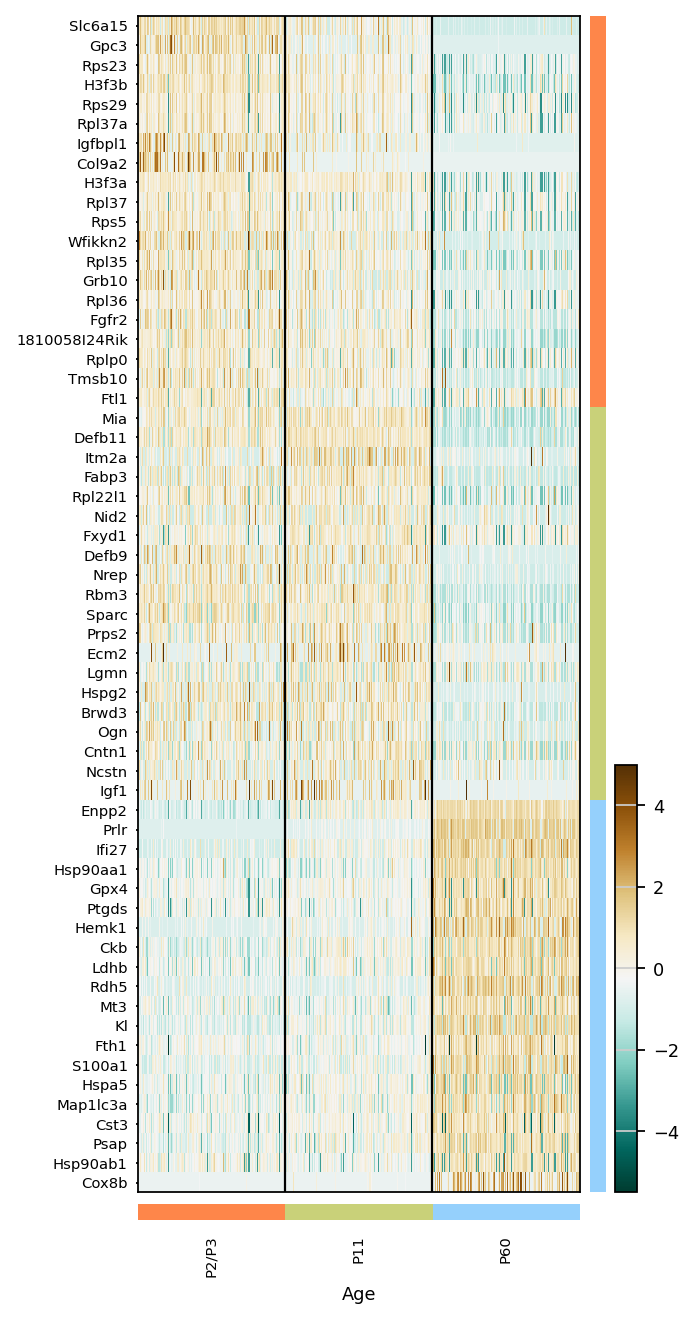

In [81]:
sc.pl.rank_genes_groups_heatmap(Epithelial_cells, n_genes=20, key="wilcoxon_Age", groupby="Age", 
                                show_gene_labels=True, use_raw=False, layer='scaled', dendrogram=False, 
                                swap_axes=True, vmax=-5, vmin=5, cmap='BrBG_r', values_to_plot='logfoldchanges', 
                                min_logfoldchange=0.5, figsize=(4,10), save='_Top_markers_epithelial_1_5.svg')

# Endothelial cells

In [108]:
adata_raw.obs["Sub_cell_type"] = adata_raw.obs["Sub_cell_type"].replace({"Antery": "Artery"}) 

In [109]:
Endothelial_cells_all = adata_raw[adata_raw.obs["Sub_cell_type"].isin(['Vein', 'Capilary', 'Artery'])]

In [110]:
Endothelial_cells_all_p2p3 = Endothelial_cells_all[Endothelial_cells_all.obs['Age']=='P2/P3']

Endothelial_cells_all_p11 = Endothelial_cells_all[Endothelial_cells_all.obs['Age']=='P11']

Endothelial_cells_all_p60 = Endothelial_cells_all[Endothelial_cells_all.obs['Age']=='P60']

In [111]:
Endothelial_cells_all_2_3 = [Endothelial_cells_all_2_3 for Endothelial_cells_all_2_3 in Endothelial_cells_all_p2p3.obs_names]

Endothelial_cells_all_11 = [Endothelial_cells_all_11 for Endothelial_cells_all_11 in Endothelial_cells_all_p11.obs_names]

Endothelial_cells_all_60 = [Endothelial_cells_all_60 for Endothelial_cells_all_60 in Endothelial_cells_all_p60.obs_names]


print(f"Endothelial_cells from P2/P3 {len(Endothelial_cells_all_2_3)}\nEndothelial_cells from P11 {len(Endothelial_cells_all_11)}\nEndothelial_cells from P60 {len(Endothelial_cells_all_60)}")

Endothelial_cells from P2/P3 324
Endothelial_cells from P11 553
Endothelial_cells from P60 949


In [112]:
import random
random_Endothelial_cells_p2p3 = random.sample(Endothelial_cells_all_2_3, 320)

random_Endothelial_cells_p11 = random.sample(Endothelial_cells_all_11, 320)

random_Endothelial_cells_p60 = random.sample(Endothelial_cells_all_60, 320)

print(f"Endothelial_cells from P2/P3 {len(random_Endothelial_cells_p2p3)}\nEndothelial_cells from P11 {len(random_Endothelial_cells_p11)}\nEndothelial_cells from P60 {len(random_Endothelial_cells_p60)}")

Endothelial_cells from P2/P3 320
Endothelial_cells from P11 320
Endothelial_cells from P60 320


In [113]:
random_Endothelial_cells = random_Endothelial_cells_p2p3 + random_Endothelial_cells_p11 + random_Endothelial_cells_p60

In [114]:
len(random_Endothelial_cells)

960

In [115]:
Endothelial_cells = Endothelial_cells_all[random_Endothelial_cells,:]

In [117]:
sc.pp.normalize_per_cell(Endothelial_cells,counts_per_cell_after=1e4)
sc.pp.log1p(Endothelial_cells)
Endothelial_cells.layers['scaled'] = sc.pp.scale(Endothelial_cells, copy=True).X

normalizing by total count per cell
    finished (0:00:00): normalized adata.X and added    'n_counts', counts per cell before normalization (adata.obs)
... as `zero_center=True`, sparse input is densified and may lead to large memory consumption


/proj/snic2020-15-248/private/Analysis/Monica/myconda_ens/rp_scrnaseq/lib/python3.8/site-packages/scanpy/preprocessing/_simple.py:524: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[key_n_counts] = counts_per_cell


## QC check

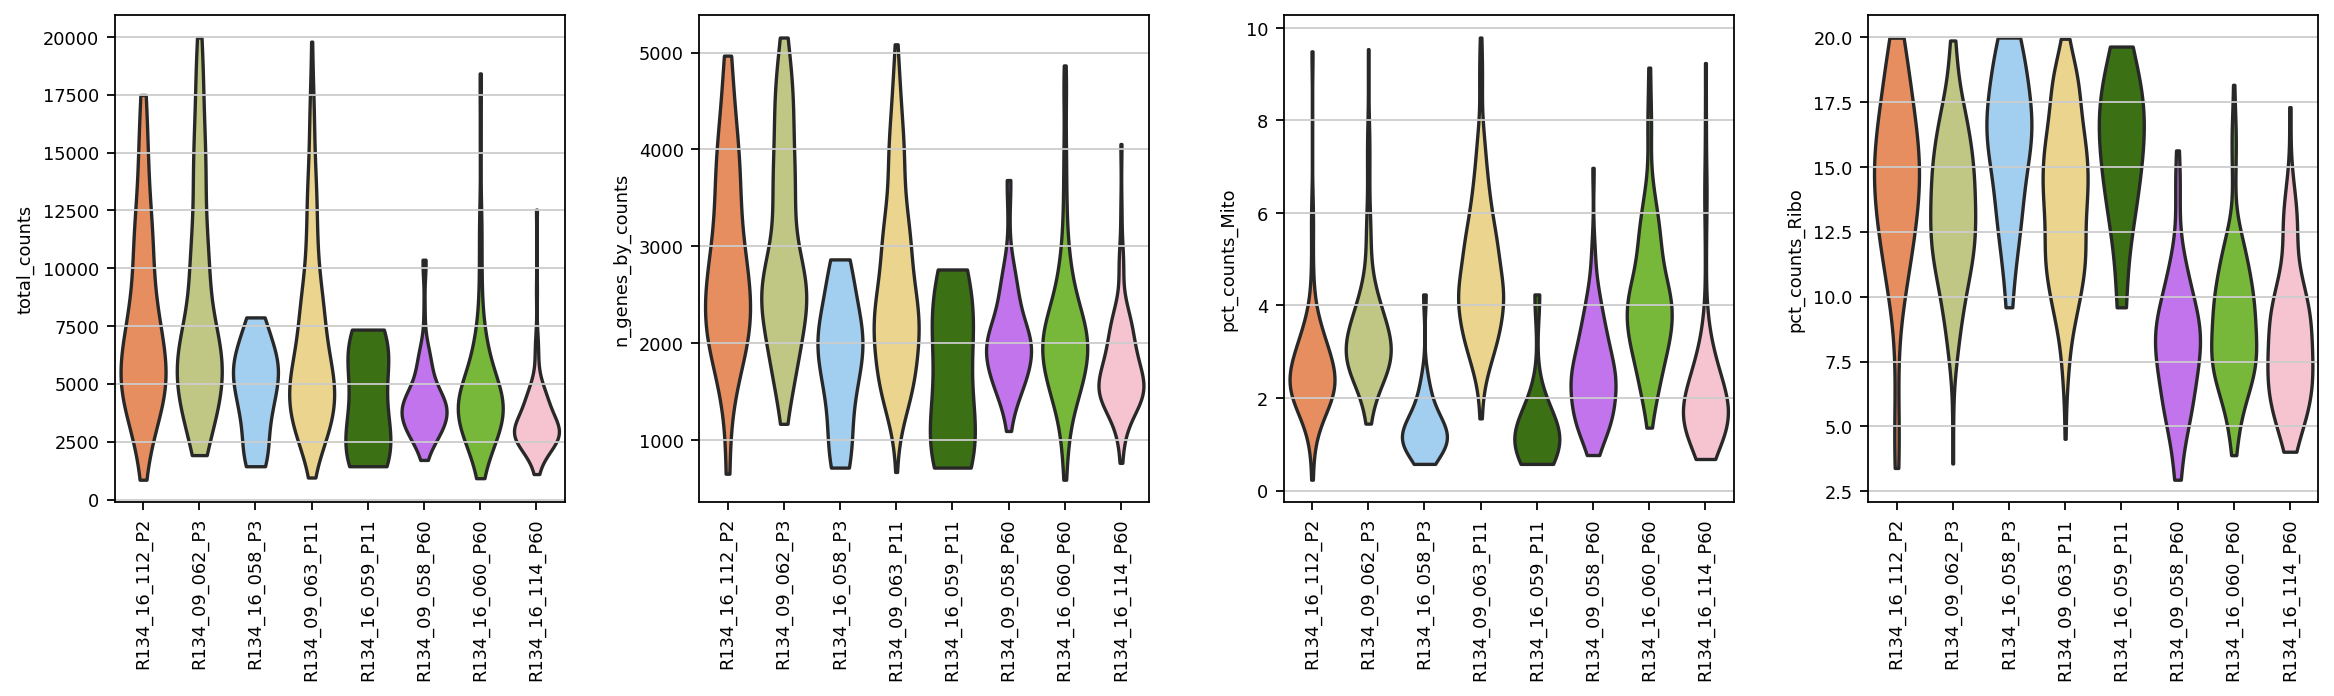

normalizing counts per cell
    finished (0:00:00)


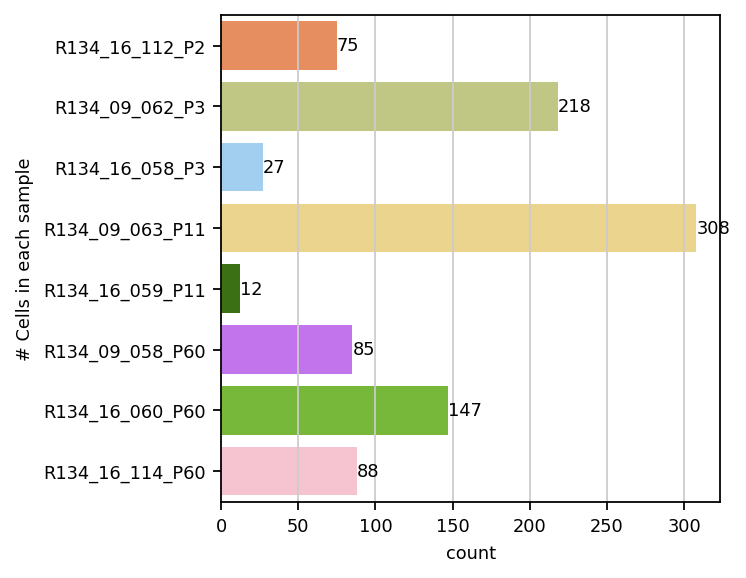

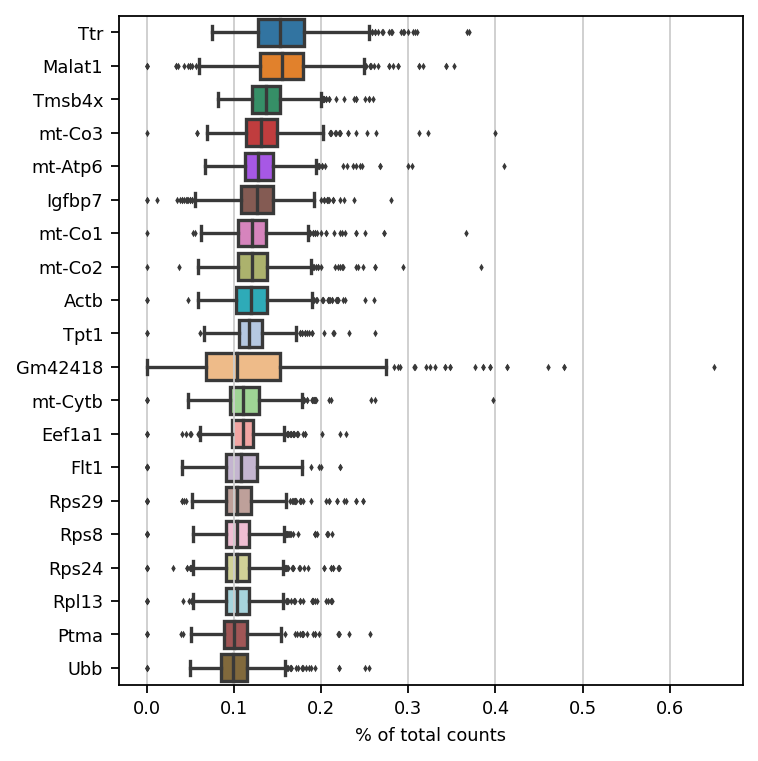

In [118]:
sc.pl.violin(Endothelial_cells, keys=['total_counts', 'n_genes_by_counts', 'pct_counts_Mito', 'pct_counts_Ribo'],
                 rotation=90, stripplot=False, jitter=0.4, multi_panel=True, groupby='batch', palette=my_c)

ax = sns.countplot(y='batch', data=Endothelial_cells.obs, palette=my_c)
ax.set_ylabel('# Cells in each sample')

for container in ax.containers:
    ax.bar_label(container)
    
sc.pl.highest_expr_genes(Endothelial_cells, n_top=20)

## DGEs from wilcoxon

In [119]:
sc.tl.rank_genes_groups(Endothelial_cells, groupby='Age', groups=['P2/P3','P60'], reference='P60',
                        method='wilcoxon', key_added="wilcoxon_P2_P3vsP60", pts=True, use_raw=False)
sc.tl.rank_genes_groups(Endothelial_cells, groupby='Age', groups=['P2/P3','P60'], reference='P2/P3',
                        method='wilcoxon', key_added="wilcoxon_P60vsP2_P3", pts=True, use_raw=False)

sc.tl.rank_genes_groups(Endothelial_cells, groupby='Age', groups=['P11','P60'], reference='P60', method='wilcoxon', 
                        key_added="wilcoxon_P11vsP60", pts=True, use_raw=False)
sc.tl.rank_genes_groups(Endothelial_cells, groupby='Age', groups=['P11','P60'], reference='P11', method='wilcoxon', 
                        key_added="wilcoxon_P60vsP11", pts=True, use_raw=False)

sc.tl.rank_genes_groups(Endothelial_cells, groupby='Age', groups=['P2/P3','P11'], reference='P11', method='wilcoxon',
                        key_added="wilcoxon_P2_P3vsP11", pts=True, use_raw=False)
sc.tl.rank_genes_groups(Endothelial_cells, groupby='Age', groups=['P2/P3','P11'], reference='P2/P3', method='wilcoxon',
                        key_added="wilcoxon_P11vsP2_P3", pts=True, use_raw=False)

sc.tl.rank_genes_groups(Endothelial_cells, groupby='Age', method='wilcoxon', key_added="wilcoxon_Age", pts=True,
                        use_raw=False)


ranking genes
    finished: added to `.uns['wilcoxon_P2_P3vsP60']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:01)
ranking genes
    finished: added to `.uns['wilcoxon_P60vsP2_P3']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:01)
ranking genes
    finished: added to `.uns['wilcoxon_P11vsP60']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to 

In [ ]:
def rank_genes_groups_df(adata_file, wilcoxon_key,group,stage_comparison): #eg: stage_comparison='P2_P3vsP60'
    groupby = adata_file.uns[wilcoxon_key]['params']['groupby']
    cols = []
    # inner loop to make data frame by concatenating the columns per group
    for col in adata_file.uns[wilcoxon_key].keys():
        if col != 'params':
            cols.append(pd.DataFrame(adata_file.uns[wilcoxon_key][col][group], columns=[col]))
    #remove existing df file
    df = pd.concat(cols,axis=1)
    df['group'] = stage_comparison
    df = df[df['pvals_adj']<0.05]
    df = df[df['logfoldchanges']>0.5]
    df.to_csv('Endothelial_cells/Downsampling/%s_markers.csv'%stage_comparison)
    return df

P2_P3vsP60 = rank_genes_groups_df(Endothelial_cells,'wilcoxon_P2_P3vsP60','P2/P3','P2_P3vsP60')
P60vsP2_P3 = rank_genes_groups_df(Endothelial_cells,'wilcoxon_P60vsP2_P3','P60','P60vsP2_P3')

P11vsP60 = rank_genes_groups_df(Endothelial_cells,'wilcoxon_P11vsP60','P11','P11vsP60')
P60vsP11 = rank_genes_groups_df(Endothelial_cells,'wilcoxon_P60vsP11','P60','P60vsP11')

P2_P3vsP11 = rank_genes_groups_df(Endothelial_cells,'wilcoxon_P2_P3vsP11','P2/P3','P2_P3vsP11')
P11vsP2_P3 = rank_genes_groups_df(Endothelial_cells,'wilcoxon_P11vsP2_P3','P11','P11vsP2_P3')

## Visualization

**Top markers**

***Markers with logfoldchanges>1.5***


In [122]:
Endothelial_cells.uns['Age_colors'] = ['#fe864a', '#c9d179', '#95d0fc']

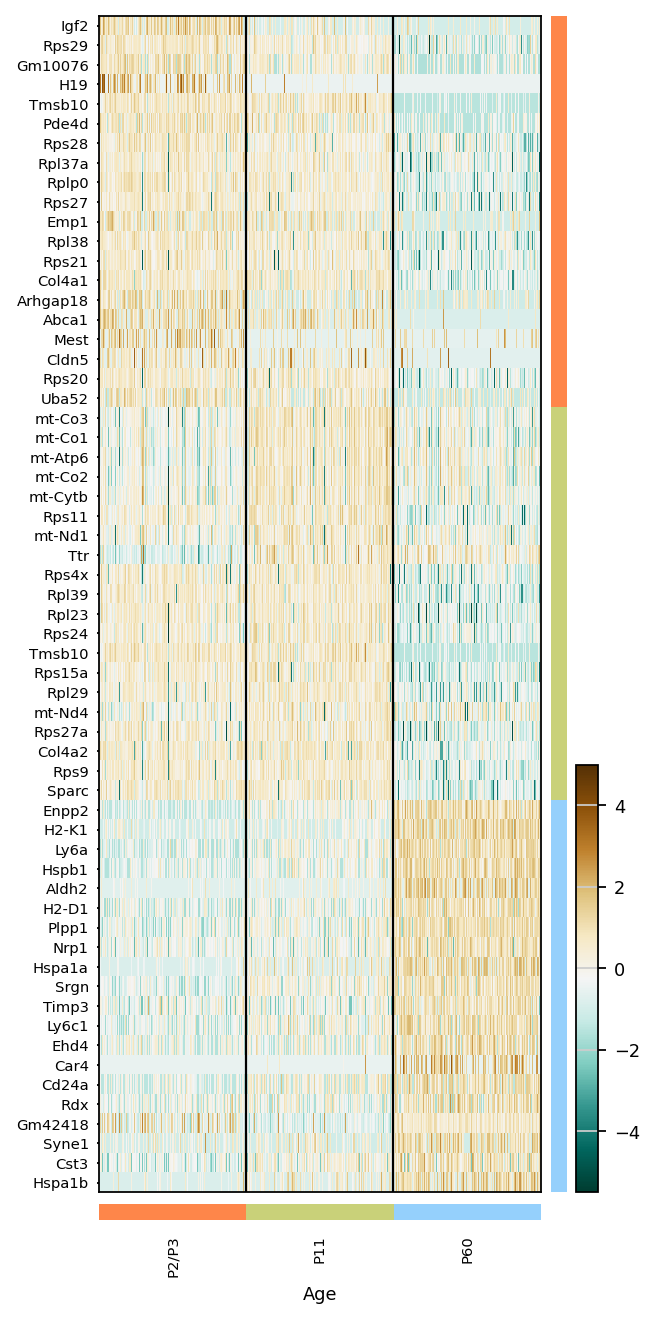

In [123]:
sc.pl.rank_genes_groups_heatmap(Endothelial_cells, n_genes=20, key="wilcoxon_Age", groupby="Age", 
                                show_gene_labels=True, use_raw=False, layer='scaled', dendrogram=False, swap_axes=True, vmax=-5, 
                                vmin=5, cmap='BrBG_r', values_to_plot='logfoldchanges', min_logfoldchange=0.5,
                                figsize=(4,10), save='_Top_markers_Endothelial_1_5.svg')

# Fibroblasts

In [134]:
Fibroblasts_all = adata_raw[adata_raw.obs['Sub_cell_type']=='Fibroblasts']

In [135]:
Fibroblasts_all_p2p3 = Fibroblasts_all[Fibroblasts_all.obs['Age']=='P2/P3']

Fibroblasts_all_p11 = Fibroblasts_all[Fibroblasts_all.obs['Age']=='P11']

Fibroblasts_all_p60 = Fibroblasts_all[Fibroblasts_all.obs['Age']=='P60']

In [136]:
Fibroblasts_all_2_3 = [Fibroblasts_all_2_3 for Fibroblasts_all_2_3 in Fibroblasts_all_p2p3.obs_names]

Fibroblasts_all_11 = [Fibroblasts_all_11 for Fibroblasts_all_11 in Fibroblasts_all_p11.obs_names]

Fibroblasts_all_60 = [Fibroblasts_all_60 for Fibroblasts_all_60 in Fibroblasts_all_p60.obs_names]


print(f"Fibroblasts from P2/P3 {len(Fibroblasts_all_2_3)}\nFibroblasts from P11 {len(Fibroblasts_all_11)}\nFibroblasts from P60 {len(Fibroblasts_all_60)}")

Fibroblasts from P2/P3 735
Fibroblasts from P11 839
Fibroblasts from P60 683


In [137]:
import random
random_Fibroblasts_p2p3 = random.sample(Fibroblasts_all_2_3, 680)

random_Fibroblasts_p11 = random.sample(Fibroblasts_all_11, 680)

random_Fibroblasts_p60 = random.sample(Fibroblasts_all_60, 680)

print(f"Fibroblasts from P2/P3 {len(random_Fibroblasts_p2p3)}\nFibroblasts from P11 {len(random_Fibroblasts_p11)}\nFibroblasts from P60 {len(random_Fibroblasts_p60)}")

Fibroblasts from P2/P3 680
Fibroblasts from P11 680
Fibroblasts from P60 680


In [138]:
random_Fibroblasts = random_Fibroblasts_p2p3 + random_Fibroblasts_p11 + random_Fibroblasts_p60

In [139]:
len(random_Fibroblasts)

2040

In [141]:
Fibroblasts = Fibroblasts_all[random_Fibroblasts,:]

In [142]:
sc.pp.normalize_per_cell(Fibroblasts,counts_per_cell_after=1e4)
sc.pp.log1p(Fibroblasts)
Fibroblasts.layers['scaled'] = sc.pp.scale(Fibroblasts, copy=True).X

normalizing by total count per cell
    finished (0:00:00): normalized adata.X and added    'n_counts', counts per cell before normalization (adata.obs)


/proj/snic2020-15-248/private/Analysis/Monica/myconda_ens/rp_scrnaseq/lib/python3.8/site-packages/scanpy/preprocessing/_simple.py:524: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[key_n_counts] = counts_per_cell


... as `zero_center=True`, sparse input is densified and may lead to large memory consumption


## QC check

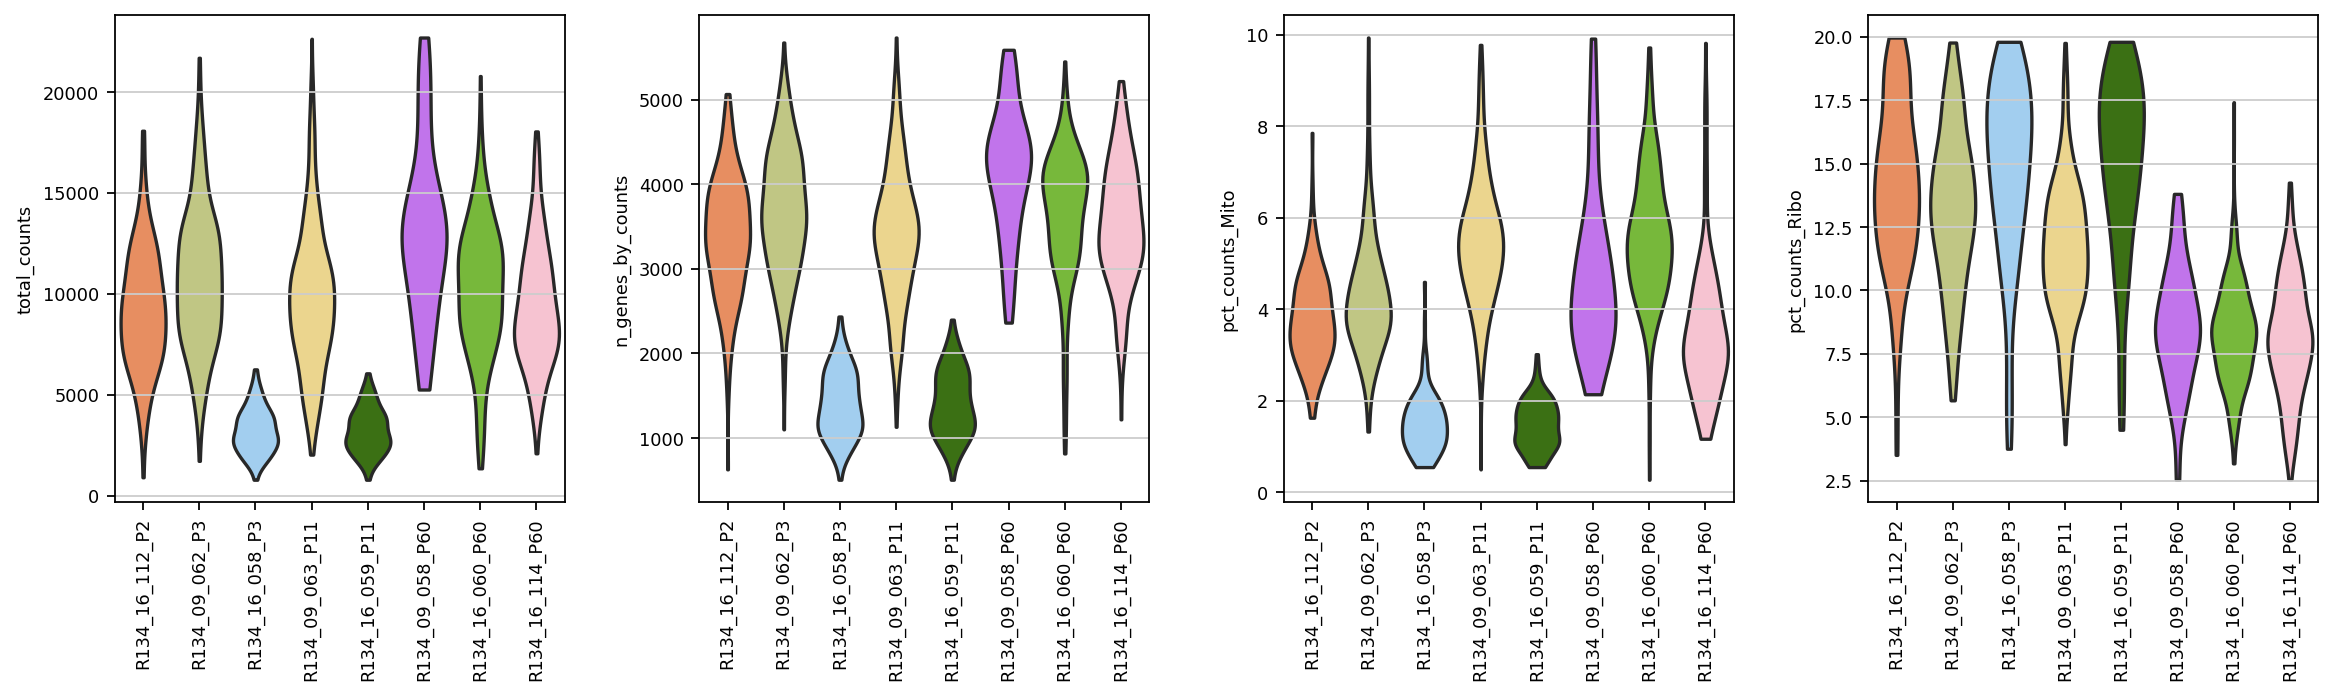

normalizing counts per cell
    finished (0:00:00)


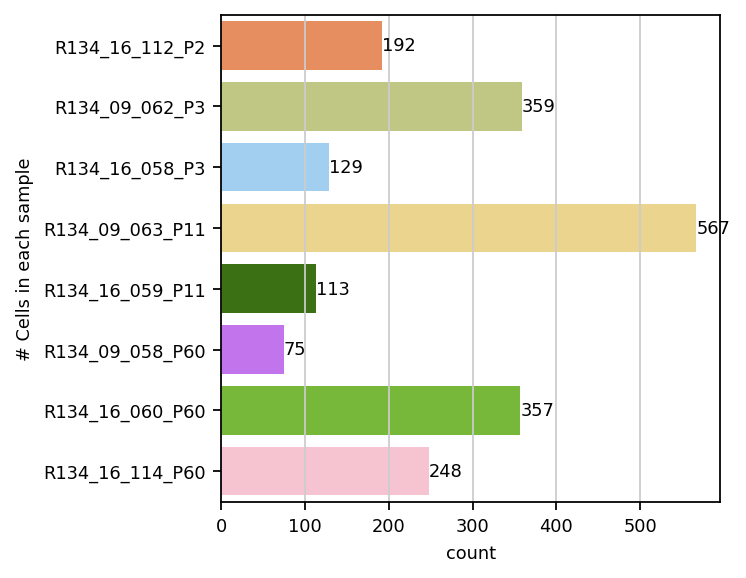

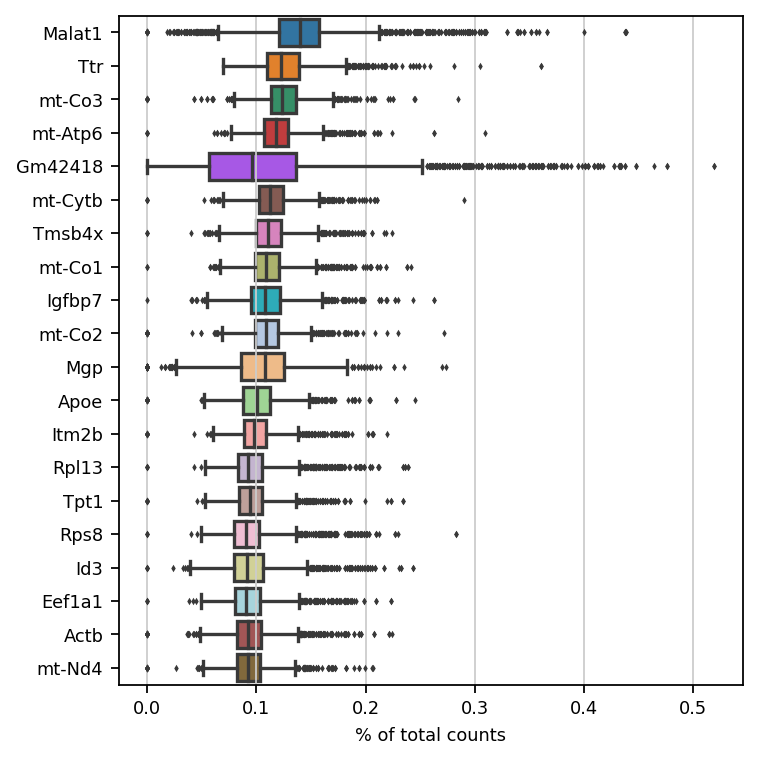

In [143]:
sc.pl.violin(Fibroblasts, keys=['total_counts', 'n_genes_by_counts', 'pct_counts_Mito', 'pct_counts_Ribo'],
                 rotation=90, stripplot=False, jitter=0.4, multi_panel=True, groupby='batch', palette=my_c)

ax = sns.countplot(y='batch', data=Fibroblasts.obs, palette=my_c)
ax.set_ylabel('# Cells in each sample')

for container in ax.containers:
    ax.bar_label(container)
    
sc.pl.highest_expr_genes(Fibroblasts, n_top=20)

## DGEs from wilcoxon

In [144]:
sc.tl.rank_genes_groups(Fibroblasts, groupby='Age', groups=['P2/P3','P60'], reference='P60',
                        method='wilcoxon', key_added="wilcoxon_P2_P3vsP60", pts=True, use_raw=False)
sc.tl.rank_genes_groups(Fibroblasts, groupby='Age', groups=['P2/P3','P60'], reference='P2/P3',
                        method='wilcoxon', key_added="wilcoxon_P60vsP2_P3", pts=True, use_raw=False)

sc.tl.rank_genes_groups(Fibroblasts, groupby='Age', groups=['P11','P60'], reference='P60', method='wilcoxon', 
                        key_added="wilcoxon_P11vsP60", pts=True, use_raw=False)
sc.tl.rank_genes_groups(Fibroblasts, groupby='Age', groups=['P11','P60'], reference='P11', method='wilcoxon', 
                        key_added="wilcoxon_P60vsP11", pts=True, use_raw=False)

sc.tl.rank_genes_groups(Fibroblasts, groupby='Age', groups=['P2/P3','P11'], reference='P11', method='wilcoxon',
                        key_added="wilcoxon_P2_P3vsP11", pts=True, use_raw=False)
sc.tl.rank_genes_groups(Fibroblasts, groupby='Age', groups=['P2/P3','P11'], reference='P2/P3', method='wilcoxon',
                        key_added="wilcoxon_P11vsP2_P3", pts=True, use_raw=False)

sc.tl.rank_genes_groups(Fibroblasts, groupby='Age', method='wilcoxon', key_added="wilcoxon_Age", pts=True,
                        use_raw=False)


ranking genes
    finished: added to `.uns['wilcoxon_P2_P3vsP60']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:04)
ranking genes
    finished: added to `.uns['wilcoxon_P60vsP2_P3']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:04)
ranking genes
    finished: added to `.uns['wilcoxon_P11vsP60']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to 

In [ ]:
def rank_genes_groups_df(adata_file, wilcoxon_key,group,stage_comparison): #eg: stage_comparison='P2_P3vsP60'
    groupby = adata_file.uns[wilcoxon_key]['params']['groupby']
    cols = []
    # inner loop to make data frame by concatenating the columns per group
    for col in adata_file.uns[wilcoxon_key].keys():
        if col != 'params':
            cols.append(pd.DataFrame(adata_file.uns[wilcoxon_key][col][group], columns=[col]))
    #remove existing df file
    df = pd.concat(cols,axis=1)
    df['group'] = stage_comparison
    df = df[df['pvals_adj']<0.05]
    df = df[df['logfoldchanges']>0.5]
    df.to_csv('Fibroblasts/Downsampling/%s_markers.csv'%stage_comparison)
    return df

P2_P3vsP60 = rank_genes_groups_df(Fibroblasts,'wilcoxon_P2_P3vsP60','P2/P3','P2_P3vsP60')
P60vsP2_P3 = rank_genes_groups_df(Fibroblasts,'wilcoxon_P60vsP2_P3','P60','P60vsP2_P3')

P11vsP60 = rank_genes_groups_df(Fibroblasts,'wilcoxon_P11vsP60','P11','P11vsP60')
P60vsP11 = rank_genes_groups_df(Fibroblasts,'wilcoxon_P60vsP11','P60','P60vsP11')

P2_P3vsP11 = rank_genes_groups_df(Fibroblasts,'wilcoxon_P2_P3vsP11','P2/P3','P2_P3vsP11')
P11vsP2_P3 = rank_genes_groups_df(Fibroblasts,'wilcoxon_P11vsP2_P3','P11','P11vsP2_P3')

## Visualization

**Top markers**

***Markers with logfoldchanges>1.5***


In [147]:
Fibroblasts.uns['Age_colors'] = ['#fe864a', '#c9d179', '#95d0fc']

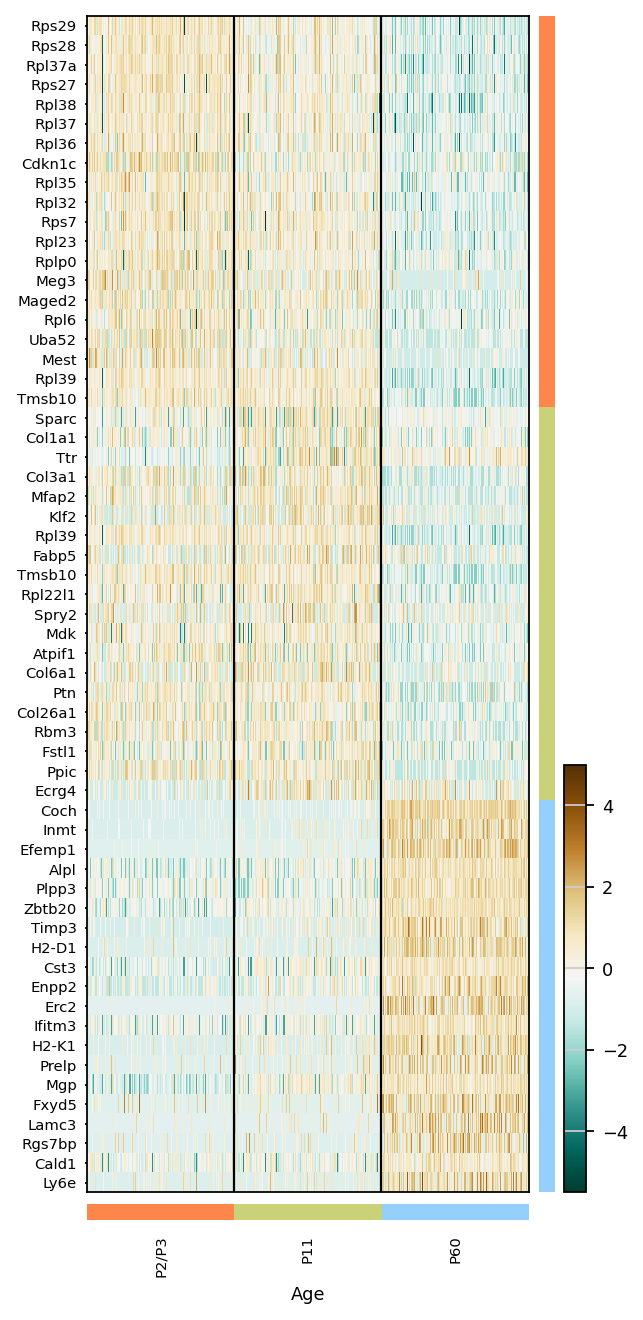

In [149]:
sc.pl.rank_genes_groups_heatmap(Fibroblasts, n_genes=20, key="wilcoxon_Age", groupby="Age", 
                                show_gene_labels=True, use_raw=False, layer='scaled', dendrogram=False, swap_axes=True, vmax=-5, 
                                vmin=5, cmap='BrBG_r', values_to_plot='logfoldchanges', min_logfoldchange=0.5,
                                figsize=(4,10), save='_Top_markers_fibroblasts_1_5.svg')

# Macrophages

In [168]:
Macrophages_all = adata_raw[adata_raw.obs['Sub_cell_type']=='Macrophages']

In [169]:
Macrophages_all_p2p3 = Macrophages_all[Macrophages_all.obs['Age']=='P2/P3']

Macrophages_all_p11 = Macrophages_all[Macrophages_all.obs['Age']=='P11']

Macrophages_all_p60 = Macrophages_all[Macrophages_all.obs['Age']=='P60']

In [170]:
Macrophages_all_2_3 = [Macrophages_all_2_3 for Macrophages_all_2_3 in Macrophages_all_p2p3.obs_names]

Macrophages_all_11 = [Macrophages_all_11 for Macrophages_all_11 in Macrophages_all_p11.obs_names]

Macrophages_all_60 = [Macrophages_all_60 for Macrophages_all_60 in Macrophages_all_p60.obs_names]


print(f"Macrophages from P2/P3 {len(Macrophages_all_2_3)}\nMacrophages from P11 {len(Macrophages_all_11)}\nMacrophages from P60 {len(Macrophages_all_60)}")

Macrophages from P2/P3 181
Macrophages from P11 234
Macrophages from P60 442


In [171]:
import random
random_Macrophages_p2p3 = random.sample(Macrophages_all_2_3, 180)

random_Macrophages_p11 = random.sample(Macrophages_all_11, 180)

random_Macrophages_p60 = random.sample(Macrophages_all_60, 180)

print(f"Macrophages from P2/P3 {len(random_Macrophages_p2p3)}\nMacrophages from P11 {len(random_Macrophages_p11)}\nMacrophages from P60 {len(random_Macrophages_p60)}")

Macrophages from P2/P3 180
Macrophages from P11 180
Macrophages from P60 180


In [172]:
random_Macrophages = random_Macrophages_p2p3 + random_Macrophages_p11 + random_Macrophages_p60

In [173]:
len(random_Macrophages)

540

In [174]:
Macrophages = Macrophages_all[random_Macrophages,:]

In [175]:
sc.pp.normalize_per_cell(Macrophages,counts_per_cell_after=1e4)
sc.pp.log1p(Macrophages)
Macrophages.layers['scaled'] = sc.pp.scale(Macrophages, copy=True).X

normalizing by total count per cell
    finished (0:00:00): normalized adata.X and added    'n_counts', counts per cell before normalization (adata.obs)
... as `zero_center=True`, sparse input is densified and may lead to large memory consumption


/proj/snic2020-15-248/private/Analysis/Monica/myconda_ens/rp_scrnaseq/lib/python3.8/site-packages/scanpy/preprocessing/_simple.py:524: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[key_n_counts] = counts_per_cell


## QC check

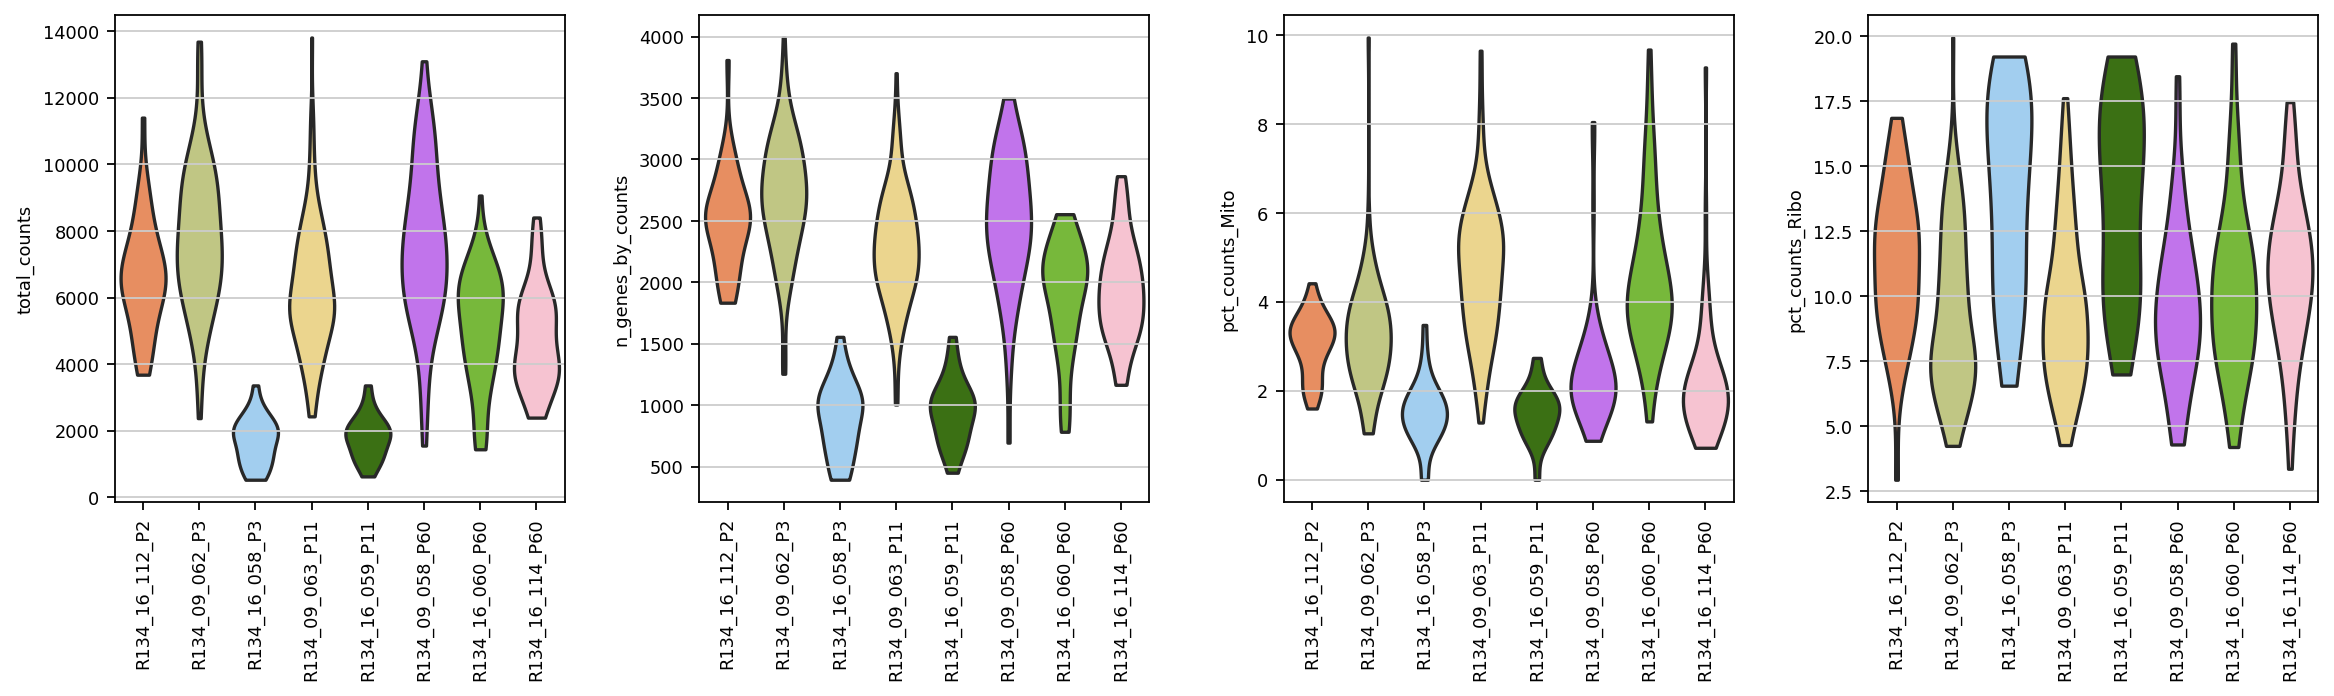

normalizing counts per cell
    finished (0:00:00)


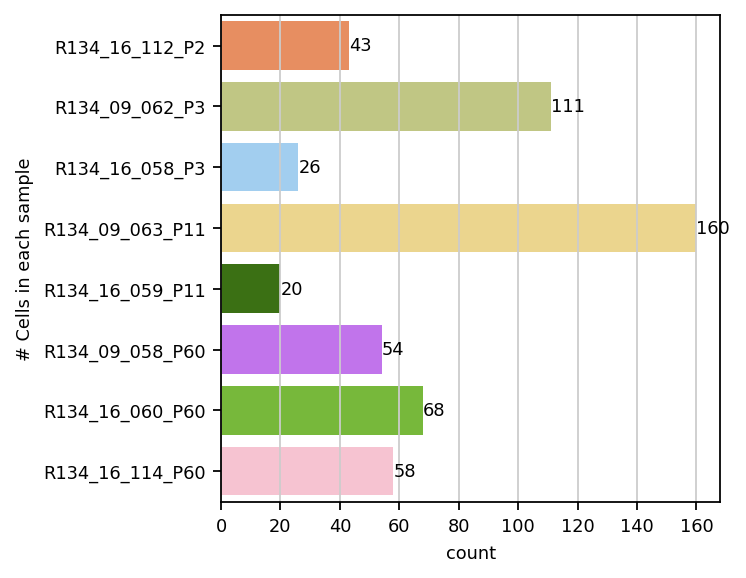

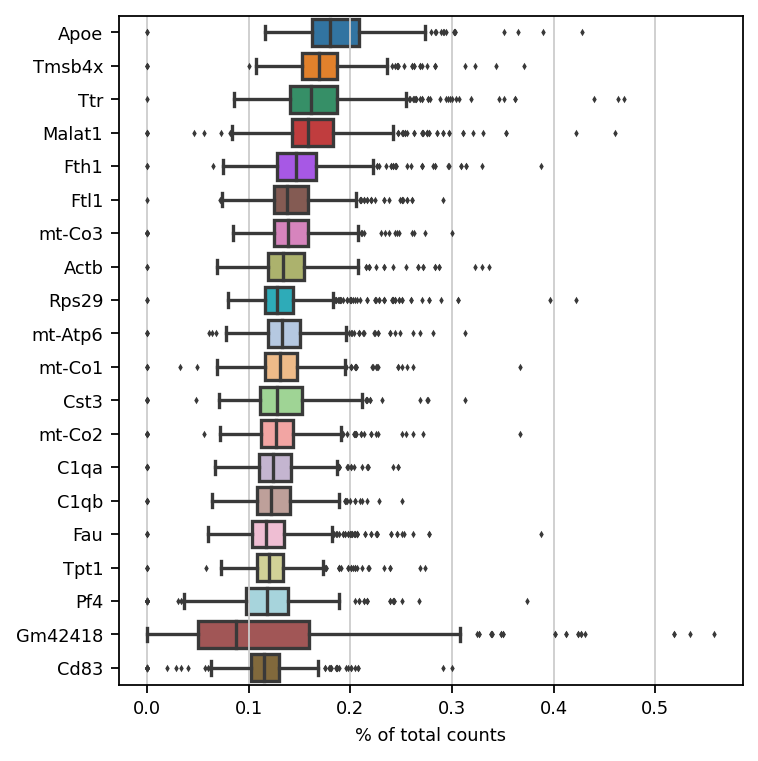

In [176]:
sc.pl.violin(Macrophages, keys=['total_counts', 'n_genes_by_counts', 'pct_counts_Mito', 'pct_counts_Ribo'],
                 rotation=90, stripplot=False, jitter=0.4, multi_panel=True, groupby='batch', palette=my_c)

ax = sns.countplot(y='batch', data=Macrophages.obs, palette=my_c)
ax.set_ylabel('# Cells in each sample')

for container in ax.containers:
    ax.bar_label(container)
    
sc.pl.highest_expr_genes(Macrophages, n_top=20)

## DGEs from wilcoxon

In [177]:
sc.tl.rank_genes_groups(Macrophages, groupby='Age', groups=['P2/P3','P60'], reference='P60',
                        method='wilcoxon', key_added="wilcoxon_P2_P3vsP60", pts=True, use_raw=False)
sc.tl.rank_genes_groups(Macrophages, groupby='Age', groups=['P2/P3','P60'], reference='P2/P3',
                        method='wilcoxon', key_added="wilcoxon_P60vsP2_P3", pts=True, use_raw=False)

sc.tl.rank_genes_groups(Macrophages, groupby='Age', groups=['P11','P60'], reference='P60', method='wilcoxon', 
                        key_added="wilcoxon_P11vsP60", pts=True, use_raw=False)
sc.tl.rank_genes_groups(Macrophages, groupby='Age', groups=['P11','P60'], reference='P11', method='wilcoxon', 
                        key_added="wilcoxon_P60vsP11", pts=True, use_raw=False)

sc.tl.rank_genes_groups(Macrophages, groupby='Age', groups=['P2/P3','P11'], reference='P11', method='wilcoxon',
                        key_added="wilcoxon_P2_P3vsP11", pts=True, use_raw=False)
sc.tl.rank_genes_groups(Macrophages, groupby='Age', groups=['P2/P3','P11'], reference='P2/P3', method='wilcoxon',
                        key_added="wilcoxon_P11vsP2_P3", pts=True, use_raw=False)

sc.tl.rank_genes_groups(Macrophages, groupby='Age', method='wilcoxon', key_added="wilcoxon_Age", pts=True,
                        use_raw=False)


ranking genes
    finished: added to `.uns['wilcoxon_P2_P3vsP60']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:01)
ranking genes
    finished: added to `.uns['wilcoxon_P60vsP2_P3']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)
ranking genes
    finished: added to `.uns['wilcoxon_P11vsP60']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to 

In [ ]:
def rank_genes_groups_df(adata_file, wilcoxon_key,group,stage_comparison): #eg: stage_comparison='P2_P3vsP60'
    groupby = adata_file.uns[wilcoxon_key]['params']['groupby']
    cols = []
    # inner loop to make data frame by concatenating the columns per group
    for col in adata_file.uns[wilcoxon_key].keys():
        if col != 'params':
            cols.append(pd.DataFrame(adata_file.uns[wilcoxon_key][col][group], columns=[col]))
    #remove existing df file
    df = pd.concat(cols,axis=1)
    df['group'] = stage_comparison
    df = df[df['pvals_adj']<0.05]
    df = df[df['logfoldchanges']>0.5]
    df.to_csv('Macrophages/Downsampling/%s_markers.csv'%stage_comparison)
    return df

P2_P3vsP60 = rank_genes_groups_df(Macrophages,'wilcoxon_P2_P3vsP60','P2/P3','P2_P3vsP60')
P60vsP2_P3 = rank_genes_groups_df(Macrophages,'wilcoxon_P60vsP2_P3','P60','P60vsP2_P3')

P11vsP60 = rank_genes_groups_df(Macrophages,'wilcoxon_P11vsP60','P11','P11vsP60')
P60vsP11 = rank_genes_groups_df(Macrophages,'wilcoxon_P60vsP11','P60','P60vsP11')

P2_P3vsP11 = rank_genes_groups_df(Macrophages,'wilcoxon_P2_P3vsP11','P2/P3','P2_P3vsP11')
P11vsP2_P3 = rank_genes_groups_df(Macrophages,'wilcoxon_P11vsP2_P3','P11','P11vsP2_P3')

## Visualization

**Top markers**

***Markers with logfoldchanges>1.5***


In [181]:
Macrophages.uns['Age_colors'] = ['#fe864a', '#c9d179', '#95d0fc']

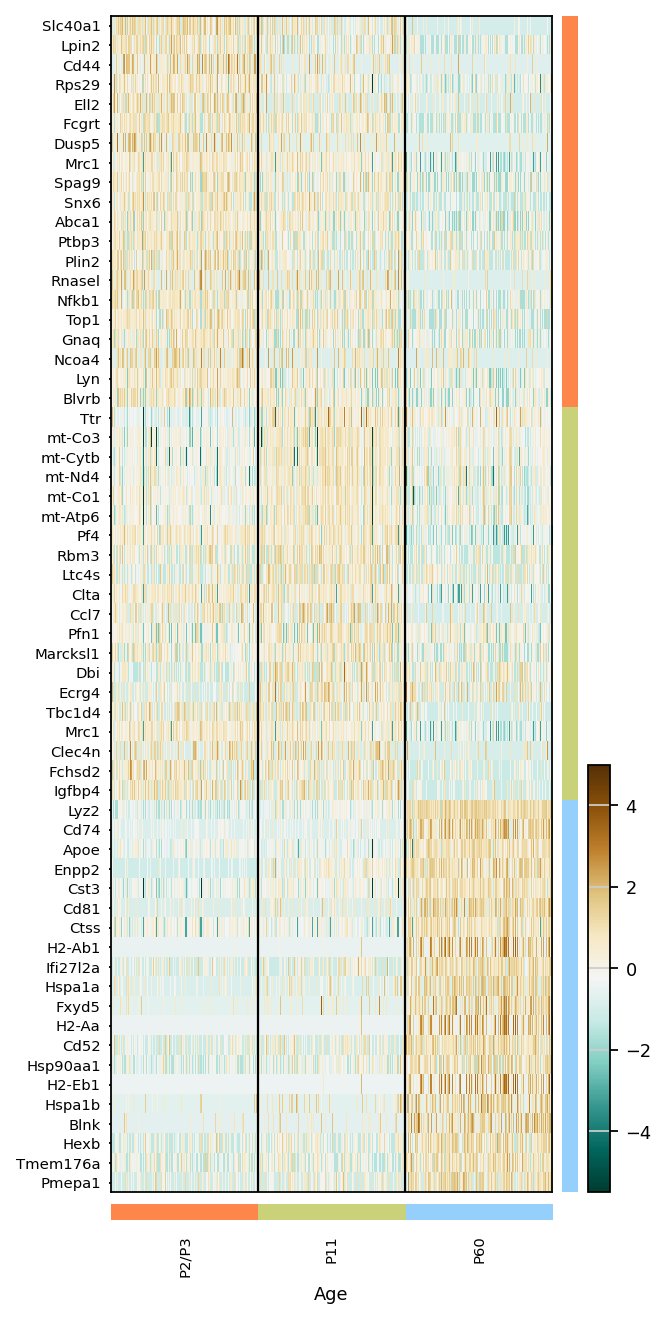

In [182]:
sc.pl.rank_genes_groups_heatmap(Macrophages, n_genes=20, key="wilcoxon_Age", groupby="Age", 
                                show_gene_labels=True, use_raw=False, layer='scaled', dendrogram=False, 
                                swap_axes=True, vmax=-5, vmin=5, cmap='BrBG_r', values_to_plot='logfoldchanges', 
                                min_logfoldchange=0.5, figsize=(4,10), save='_Top_markers_emacrophages_1_5.svg')